# YOLOv8 Cardboard Detection, Segmentation & ONNX Export

This notebook walks you through:
1. Installing Ultralytics (`yolov8`) and downloading the corrugated cardboard boxes dataset.
2. Setting up the dataset for training.
3. Fine-tuning a `yolov8n` model.
4. Evaluating the metrics.
5. Exporting the fine-tuned model to the `ONNX` format.
6. Testing the model on a sample image.

In [1]:
# Install Ultralytics and dependencies
!pip install ultralytics albumentations onnx

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.0/47.0 kB 4.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 52.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.9/8.9 MB 106.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.9/97.9 kB 11.2 MB/s eta 0:00:00


In [2]:
# Clone the dataset repository
!git clone https://github.com/chanllon/corrugated-cardboard-boxes-dataset.git

Cloning into 'corrugated-cardboard-boxes-dataset'...
remote: Enumerating objects: 2385, done.
remote: Counting objects: 100% (324/324), done.
remote: Compressing objects: 100% (18/18), done.
remote: Total 2385 (delta 311), reused 306 (delta 306), pack-reused 2061 (from 1)
Receiving objects: 100% (2385/2385), 1.49 GiB | 30.47 MiB/s, done.
Resolving deltas: 100% (983/983), done.
Updating files: 100% (2371/2371), done.


In [6]:
import os

# Let's inspect the contents of the repository to understand its structure
repo_path = 'corrugated-cardboard-boxes-dataset'
for item in os.listdir(repo_path):
    item_path = os.path.join(repo_path, item)
    if os.path.isdir(item_path):
        print(f"[DIR] {item}")
        # Print a few files inside to see the format
        print("      ->", os.listdir(item_path)[:5])
    else:
        print(f"[FILE] {item}")

[DIR] .git
      -> ['hooks', 'description', 'config', 'branches', 'packed-refs']
[FILE] README.md
[DIR] post_station
      -> ['new_256_cropped.jpg', 'new_14_cropped.jpg', 'new_216_cropped.jpg', '49.jpg', 'new_291_cropped.jpg']
[DIR] dataset3_resize
      -> ['45_1_5.jpg', '27_3_4.json', '15_2_5.json', '45_1_5.json', '48_1_4.jpg']


In [9]:
import json
import glob
import os
import shutil
import random

base_dir = 'yolo_dataset'
for split in ['train', 'val']:
    os.makedirs(f'{base_dir}/images/{split}', exist_ok=True)
    os.makedirs(f'{base_dir}/labels/{split}', exist_ok=True)

json_files = glob.glob('corrugated-cardboard-boxes-dataset/**/*.json', recursive=True)
random.seed(42)
random.shuffle(json_files)

# 80/20 train/val split
split_idx = int(len(json_files) * 0.8)
splits = {'train': json_files[:split_idx], 'val': json_files[split_idx:]}

for split, files in splits.items():
    for j_path in files:
        with open(j_path, 'r') as f:
            data = json.load(f)

        img_name = data.get('imagePath')
        dir_name = os.path.dirname(j_path)
        img_path = os.path.join(dir_name, img_name)

        if not os.path.exists(img_path):
            continue

        img_w = data.get('imageWidth')
        img_h = data.get('imageHeight')
        if not img_w or not img_h:
            continue

        labels = []
        for shape in data.get('shapes', []):
            # Only keep the 'box' label, ignore 'damage'
            if shape['label'].lower() == 'box' and shape['shape_type'] == 'rectangle':
                pts = shape['points']
                x1, y1 = pts[0]
                x2, y2 = pts[1]
                xmin, xmax = min(x1, x2), max(x1, x2)
                ymin, ymax = min(y1, y2), max(y1, y2)

                # YOLO format: normalized xc, yc, w, h
                xc = ((xmin + xmax) / 2.0) / img_w
                yc = ((ymin + ymax) / 2.0) / img_h
                w = (xmax - xmin) / img_w
                h = (ymax - ymin) / img_h
                labels.append(f"0 {xc} {yc} {w} {h}")

        dst_img = f'{base_dir}/images/{split}/{img_name}'
        dst_lbl = f'{base_dir}/labels/{split}/{os.path.splitext(img_name)[0]}.txt'

        shutil.copy(img_path, dst_img)
        with open(dst_lbl, 'w') as f:
            f.write('\n'.join(labels))

yaml_content = f"""train: {os.path.abspath(base_dir)}/images/train
val: {os.path.abspath(base_dir)}/images/val
nc: 1
names: ['box']
"""
with open(f'{base_dir}/data.yaml', 'w') as f:
    f.write(yaml_content.strip())

print(f"Dataset converted successfully. Saved to {base_dir} with only 'box' class.")

Dataset converted successfully. Saved to yolo_dataset with only 'box' class.


### Train YOLOv8n model
We will now load a pre-trained `yolov8n.pt` model (either for Object Detection or Instance Segmentation if segmentation labels are configured in the dataset) and fine-tune it.

In [10]:
import os
from ultralytics import YOLO

# Initialize a YOLOv8 Nano model (detection)
model = YOLO('yolov8n.pt')

# Use our newly generated data.yaml
yaml_path = os.path.abspath('yolo_dataset/data.yaml')
print(f"Using dataset configuration path: {yaml_path}")

# Fine-tune the model for 30 epochs as requested
results = model.train(data=yaml_path, epochs=30, imgsz=640, device='0')

Using dataset configuration path: /content/yolo_dataset/data.yaml
Ultralytics 8.4.184 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/yolo_dataset/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0

### Training Metrics & Loss Plots
Let's visualize the training results, including bounding box loss, class loss, and mAP over the 30 epochs.

Training Metrics and Loss Plots:


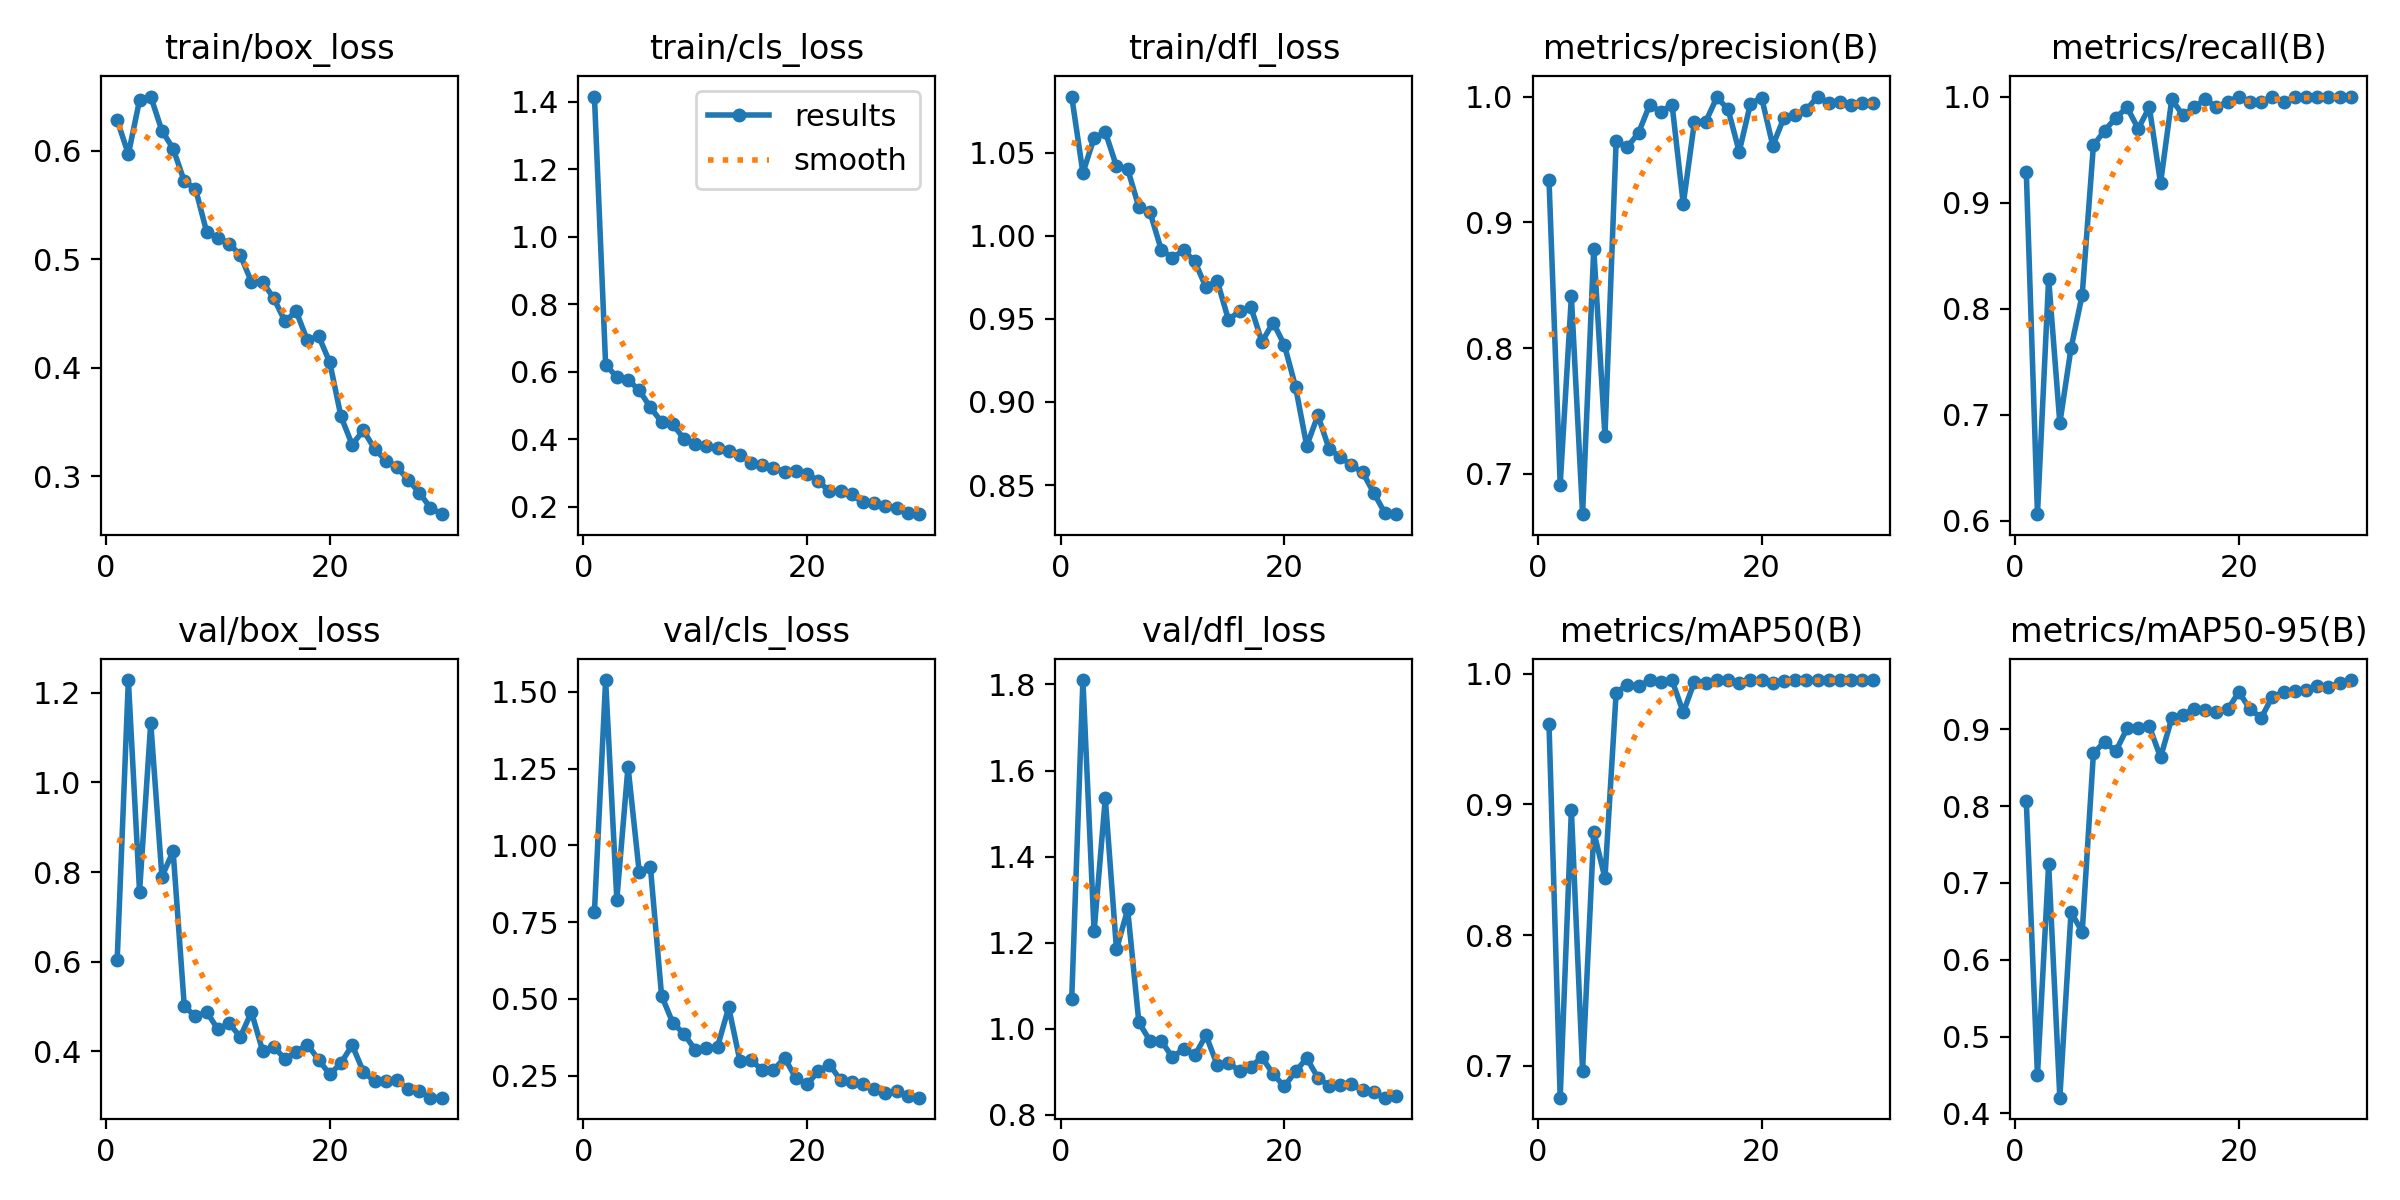

In [14]:
import os
from IPython.display import Image, display

results_img_path = '/content/runs/detect/train/results.png'

if os.path.exists(results_img_path):
    print("Training Metrics and Loss Plots:")
    display(Image(filename=results_img_path))
else:
    print(f"Could not find {results_img_path}. Here are the files in the directory:")
    train_dir = '/content/runs/detect/train/'
    if os.path.exists(train_dir):
        print(os.listdir(train_dir))
    else:
        print("Training directory does not exist.")

### Detailed Performance Metrics: Ground Truth vs Predictions
Here we will look at the actual images from the validation set.
- **Ground Truth**: The correct bounding boxes we created from the JSON files.
- **Predictions**: The bounding boxes your trained YOLO model drew.
- **Confusion Matrix**: Shows how often the model is correct vs confused.


Ground Truth Labels (Validation)


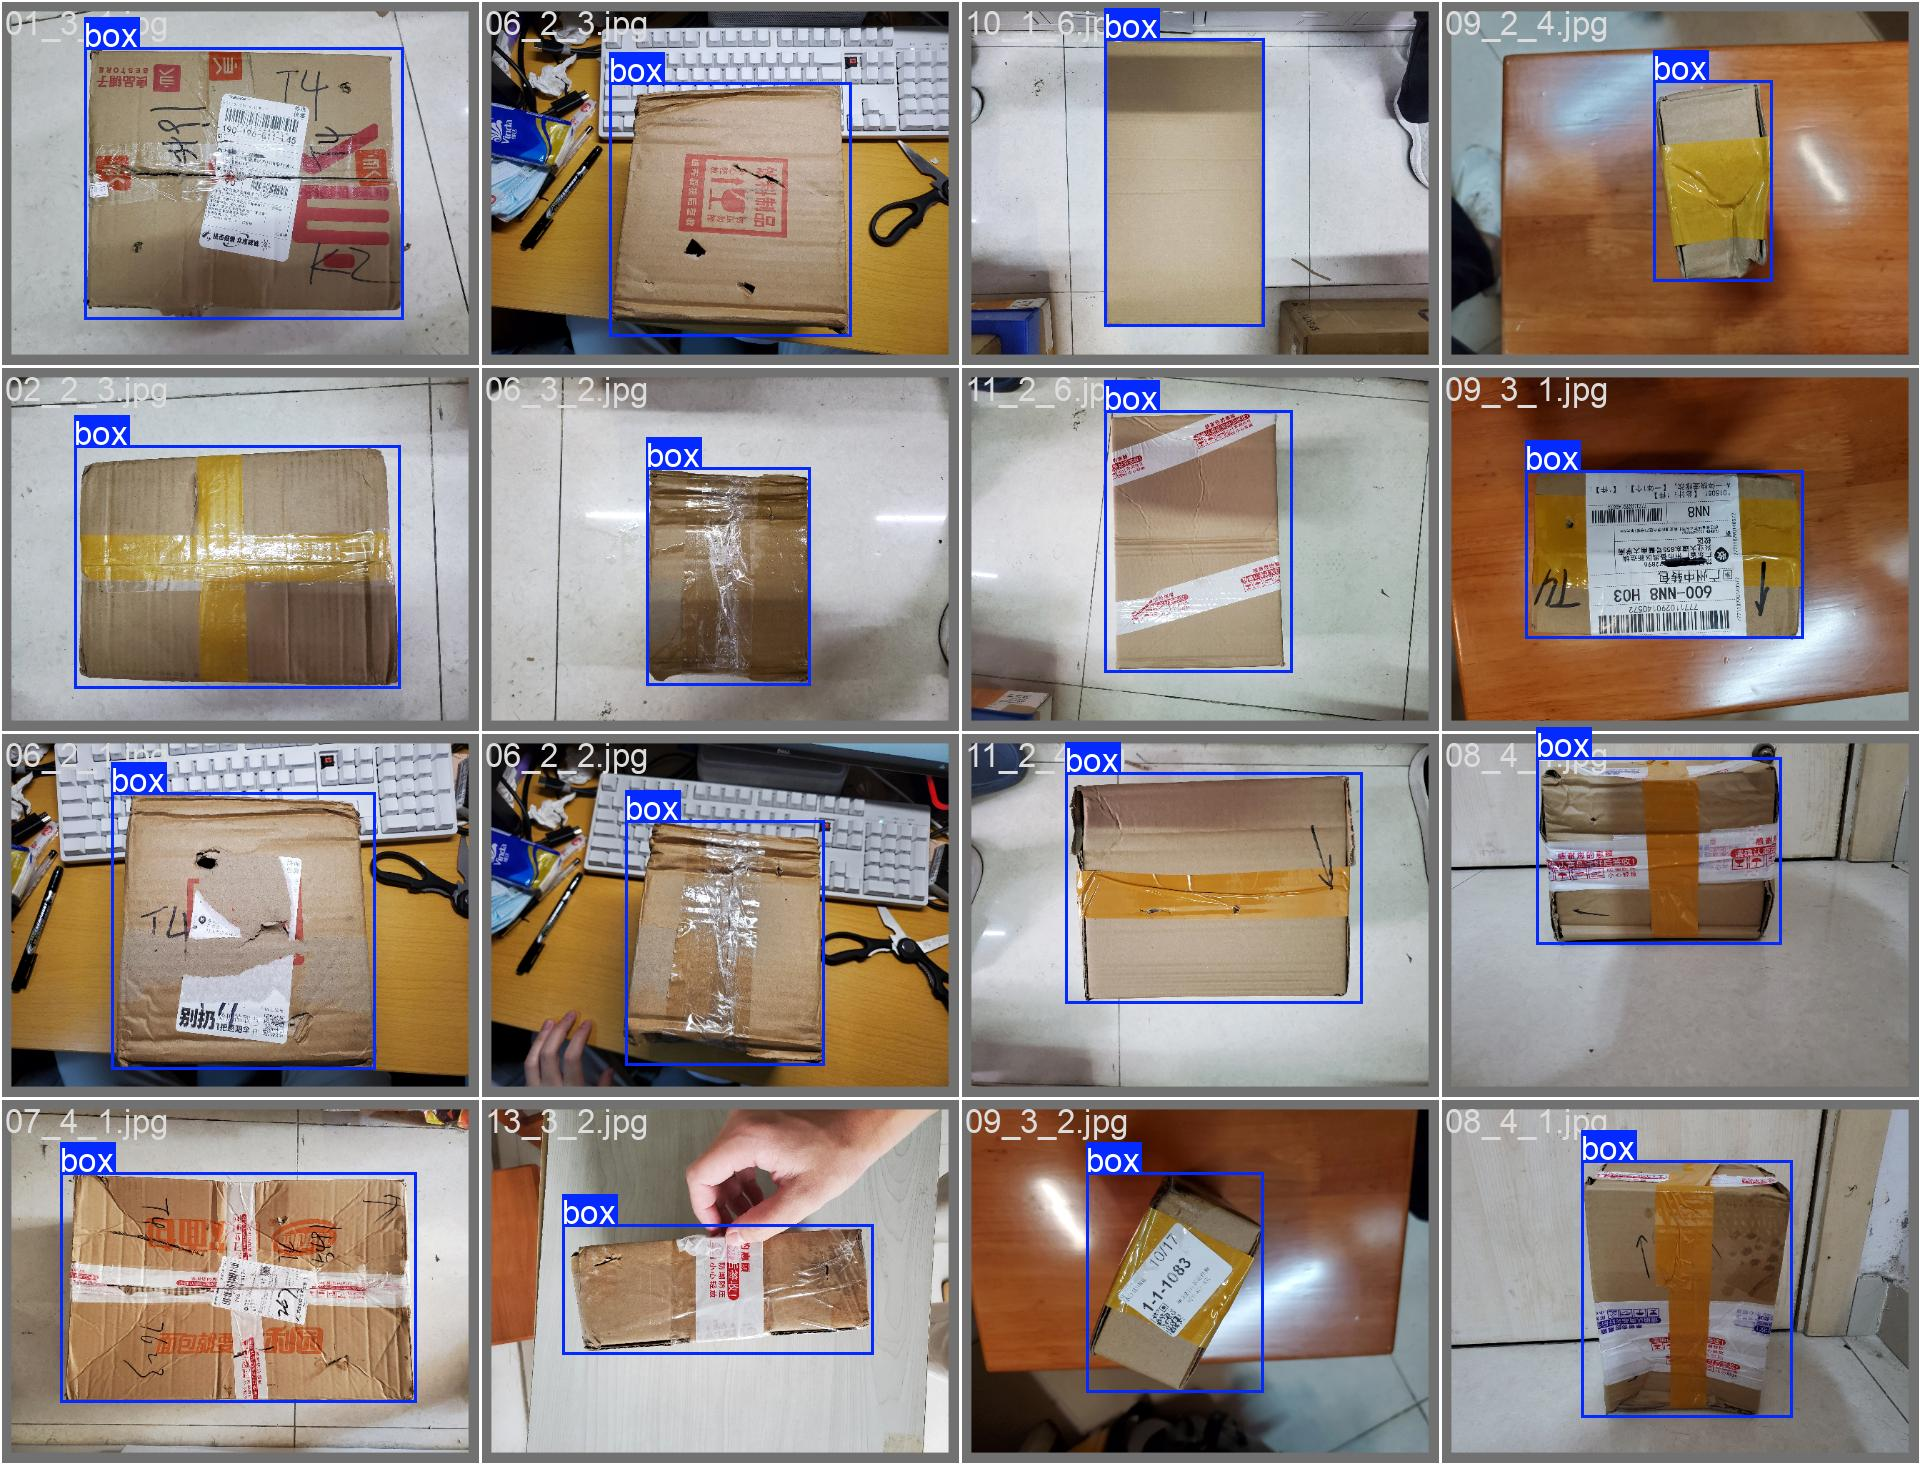


Model Predictions (Validation)


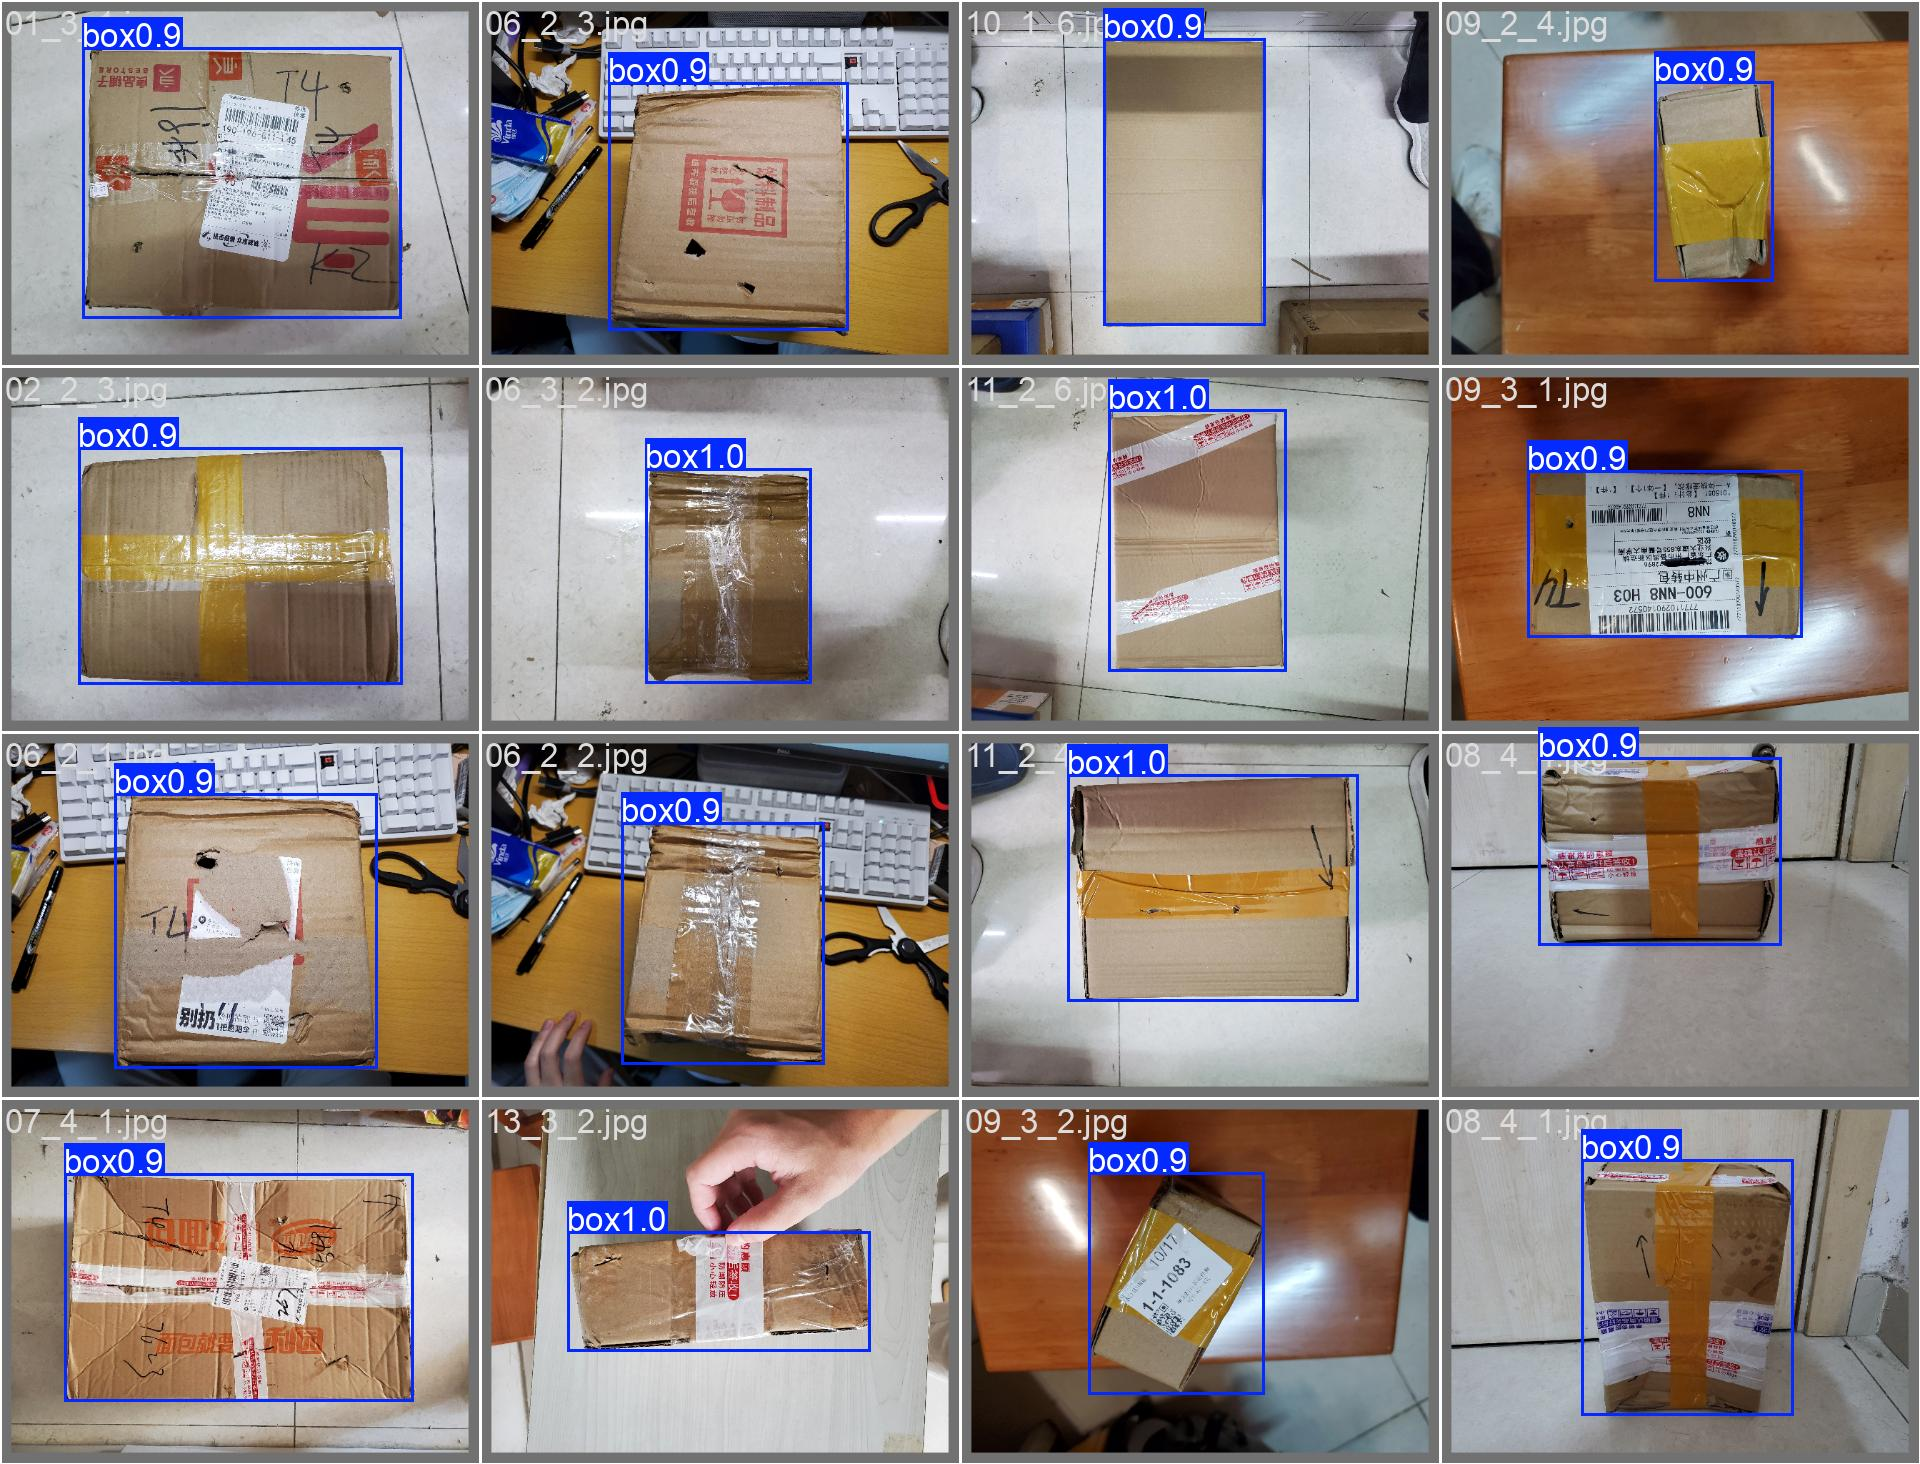


Confusion Matrix


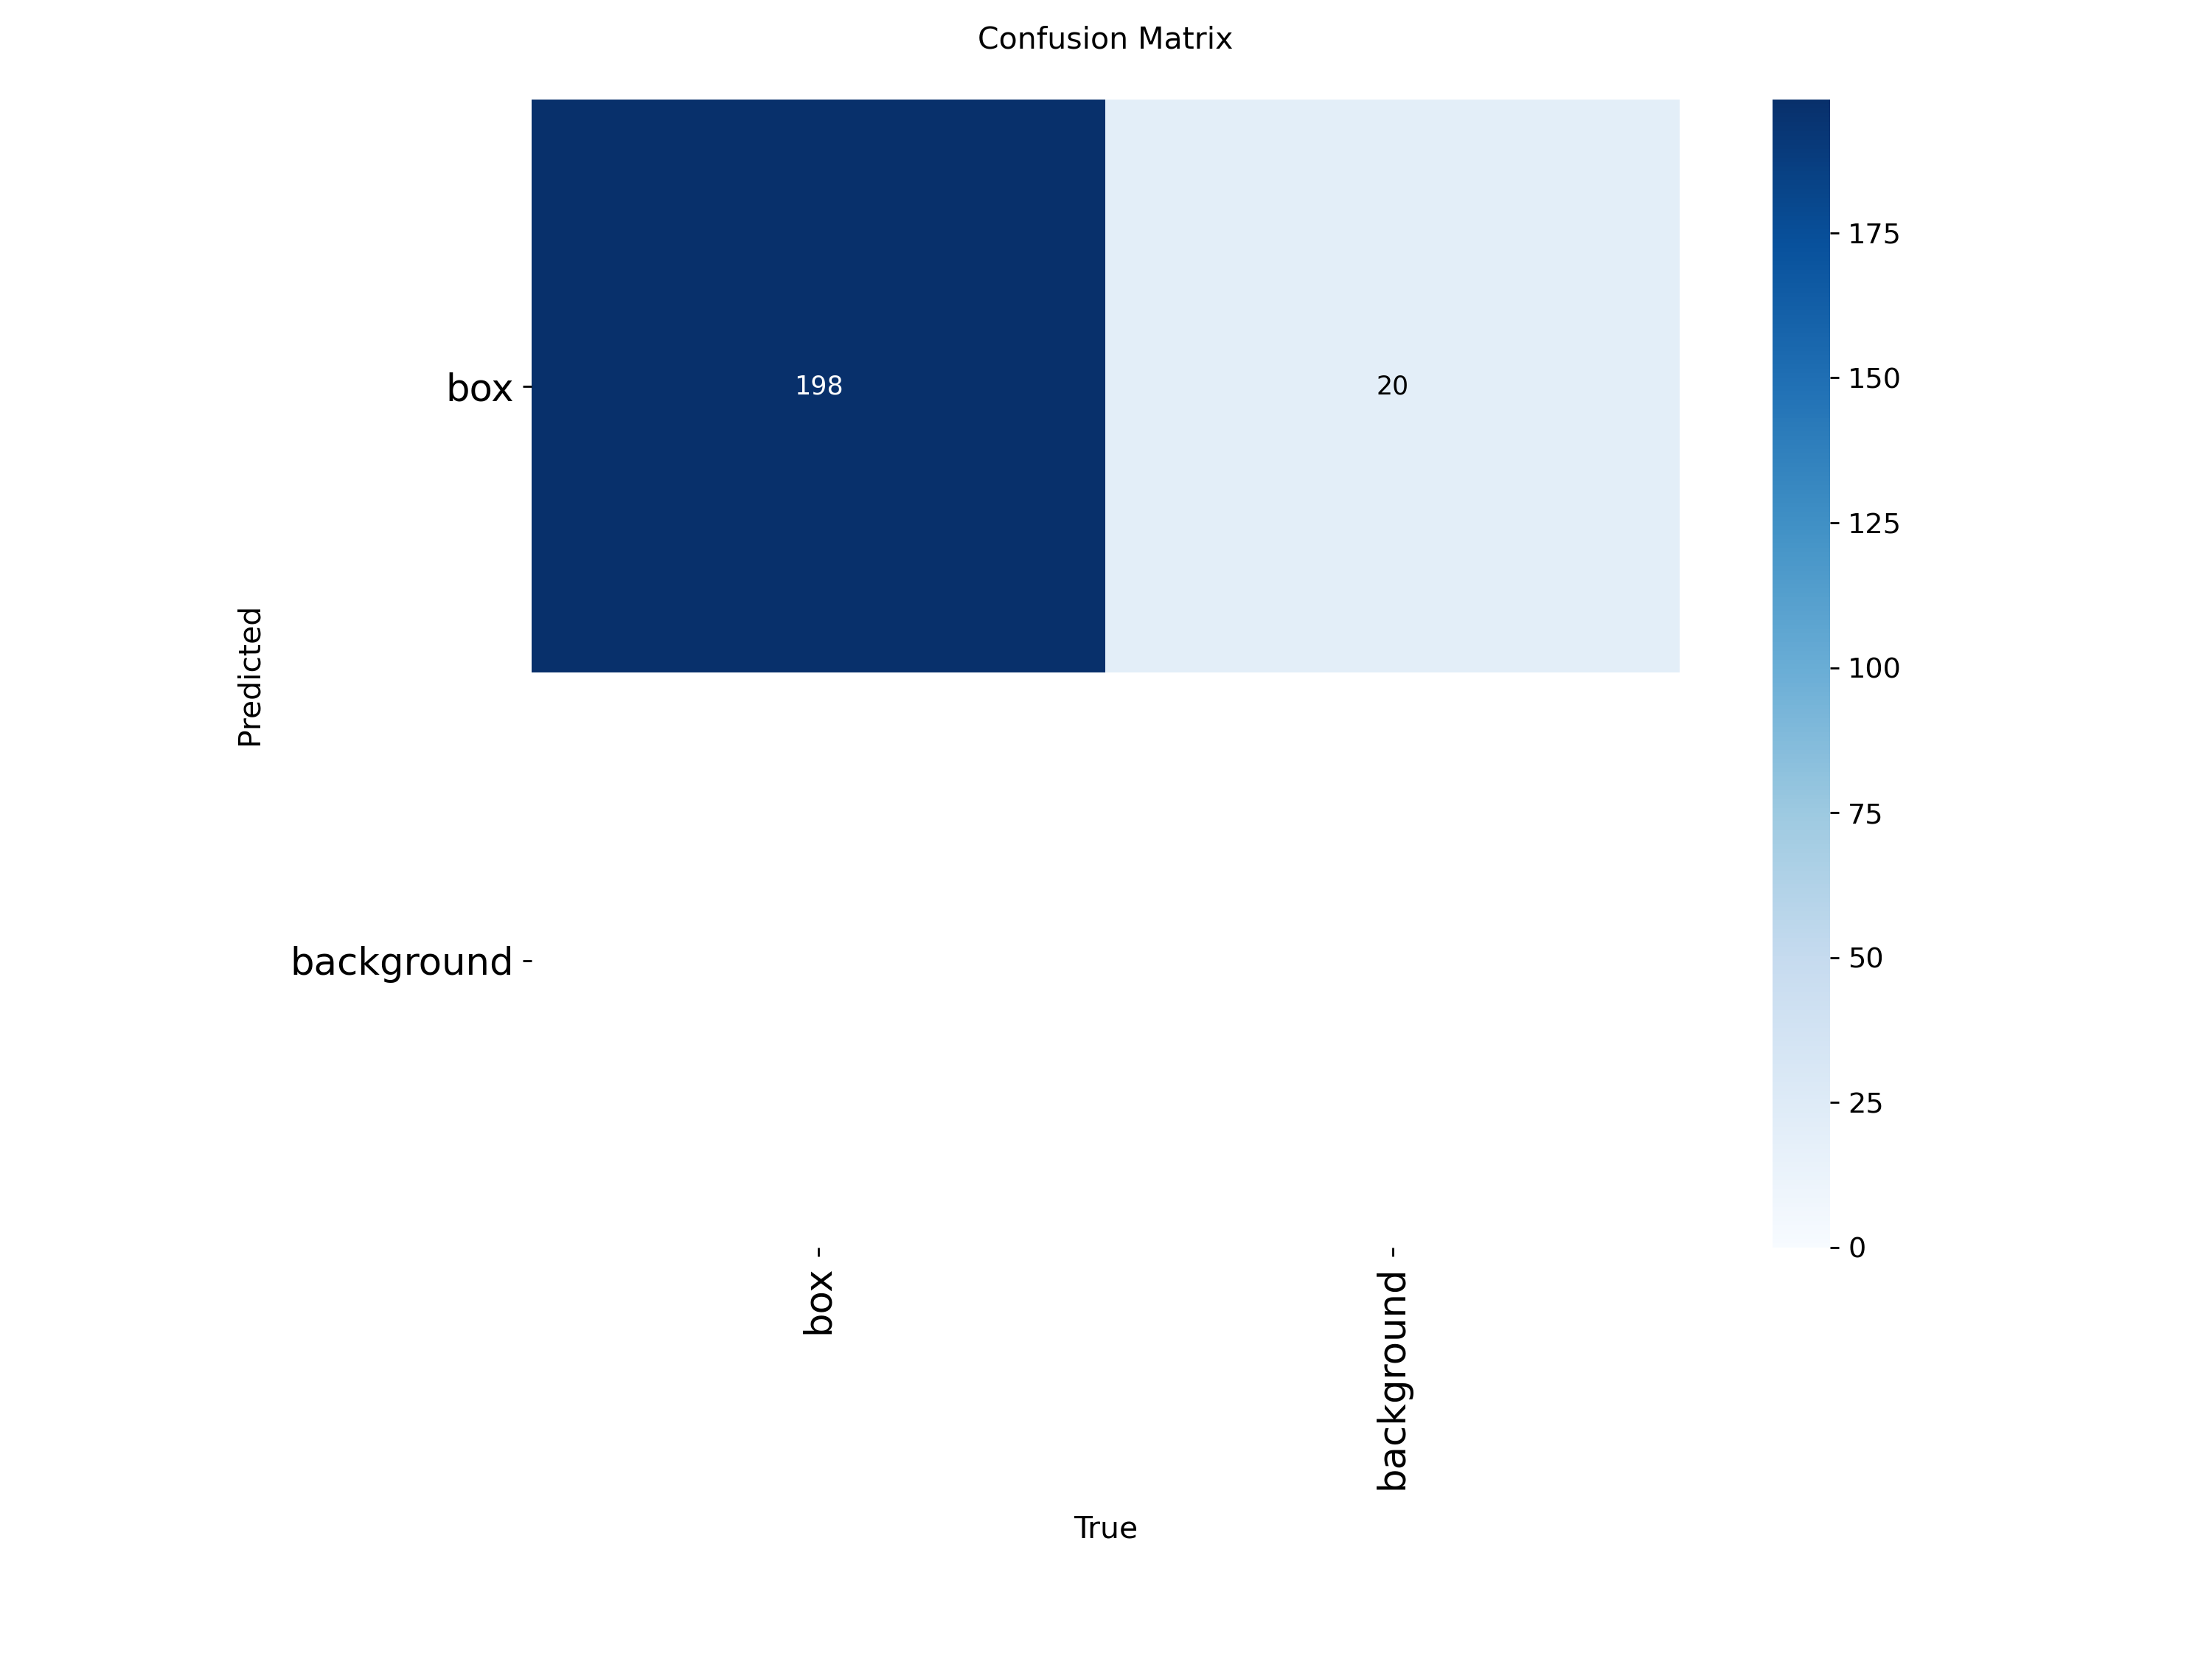

In [20]:
import os
from IPython.display import Image, display

train_dir = '/content/runs/detect/train/'

# Dictionary of useful visualizations saved by YOLO
visualizations = {
    "Ground Truth Labels (Validation)": "val_batch0_labels.jpg",
    "Model Predictions (Validation)": "val_batch0_pred.jpg",
    "Confusion Matrix": "confusion_matrix.png"
}

for title, filename in visualizations.items():
    img_path = os.path.join(train_dir, filename)
    if os.path.exists(img_path):
        print(f"\n{'='*50}\n{title}\n{'='*50}")
        display(Image(filename=img_path, width=800))
    else:
        print(f"\n[Not Found] {filename} is not available in {train_dir}")

### Export to ONNX & Run Inference
We will export our fine-tuned weights to the ONNX format and run inference on a sample image.

In [11]:
# Export the model to ONNX format
exported_path = model.export(format='onnx')
print(f"Model exported successfully to: {exported_path}")

Ultralytics 8.4.184 🚀 Python-3.13.15 torch-2.11.0+cu130 CPU (Intel Xeon CPU @ 2.00GHz)
Model summary (fused): 73 layers, 3,132,707 parameters, 0 gradients, 8.6 GFLOPs

PyTorch: starting from '/content/runs/detect/train/weights/best.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) (1, 5, 8400) (6.2 MB)

ONNX: starting export with onnx 1.23.2 opset 18...
ONNX: slimming with onnxslim 0.1.98...
ONNX: export success ✅ 1.3s, saved as '/content/runs/detect/train/weights/best.onnx' (12.2 MB)

Export complete (1.5s)
Results saved to /content/runs/detect/train/weights/best.onnx
Predict:         yolo predict task=detect model=/content/runs/detect/train/weights/best.onnx imgsz=640 
Validate:        yolo val task=detect model=/content/runs/detect/train/weights/best.onnx imgsz=640 data=/content/yolo_dataset/data.yaml 
Visualize:       https://netron.app
Model exported successfully to: /content/runs/detect/train/weights/best.onnx


Testing model on sample image: corrugated-cardboard-boxes-dataset/post_station/3.jpg

image 1/1 /content/corrugated-cardboard-boxes-dataset/post_station/3.jpg: 608x640 1 box, 14.1ms
Speed: 4.3ms preprocess, 14.1ms inference, 1.7ms postprocess per image at shape (1, 3, 608, 640)


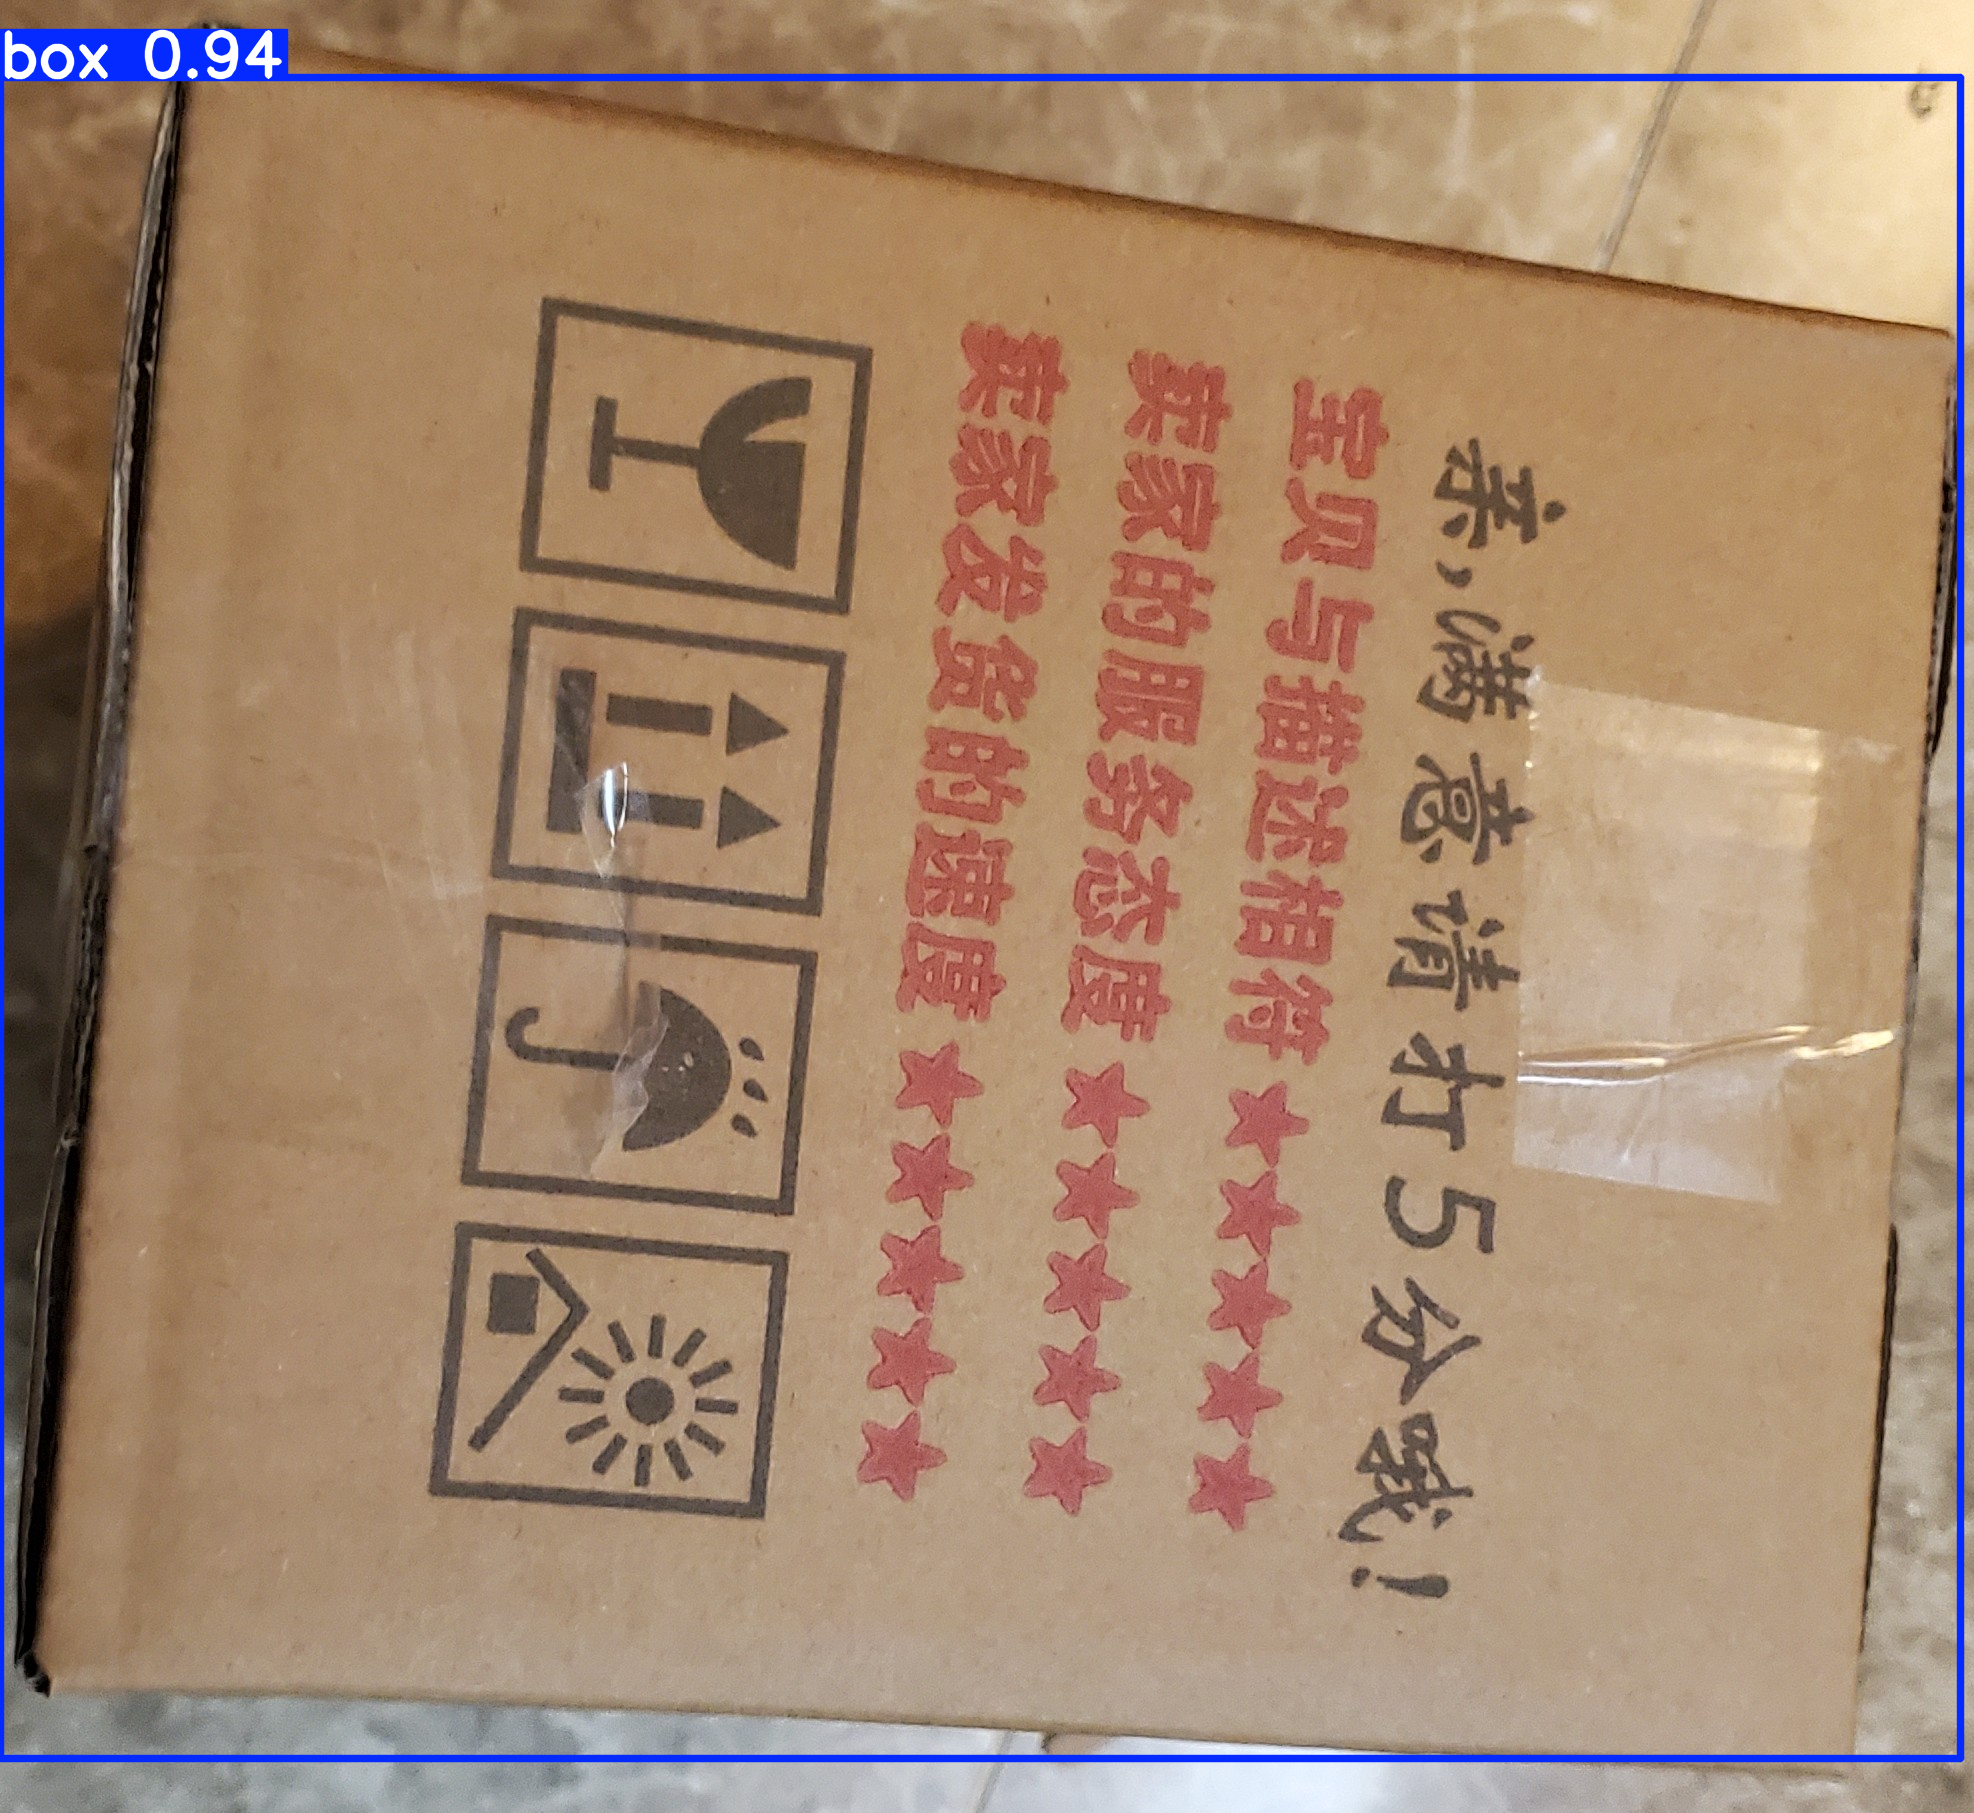

In [22]:
from PIL import Image
import glob

# Look for any sample image within the dataset directory to test
test_images = glob.glob('corrugated-cardboard-boxes-dataset/**/*.jpg', recursive=True) + \
              glob.glob('corrugated-cardboard-boxes-dataset/**/*.png', recursive=True)

if test_images:
    sample_img_path = test_images[15]
    print(f"Testing model on sample image: {sample_img_path}")

    # Run prediction using the fine-tuned model
    prediction_results = model(sample_img_path)

    # Plot and display the predictions
    for res in prediction_results:
        res_im = res.plot()
        display(Image.fromarray(res_im[:, :, ::-1])) # Convert BGR to RGB
else:
    print("No sample images found to test inference.")

### Exploratory Data Analysis (EDA)
Let's analyze the original dataset to see exactly what kind of data we have. This will give us insights into class distributions and bounding box sizes.

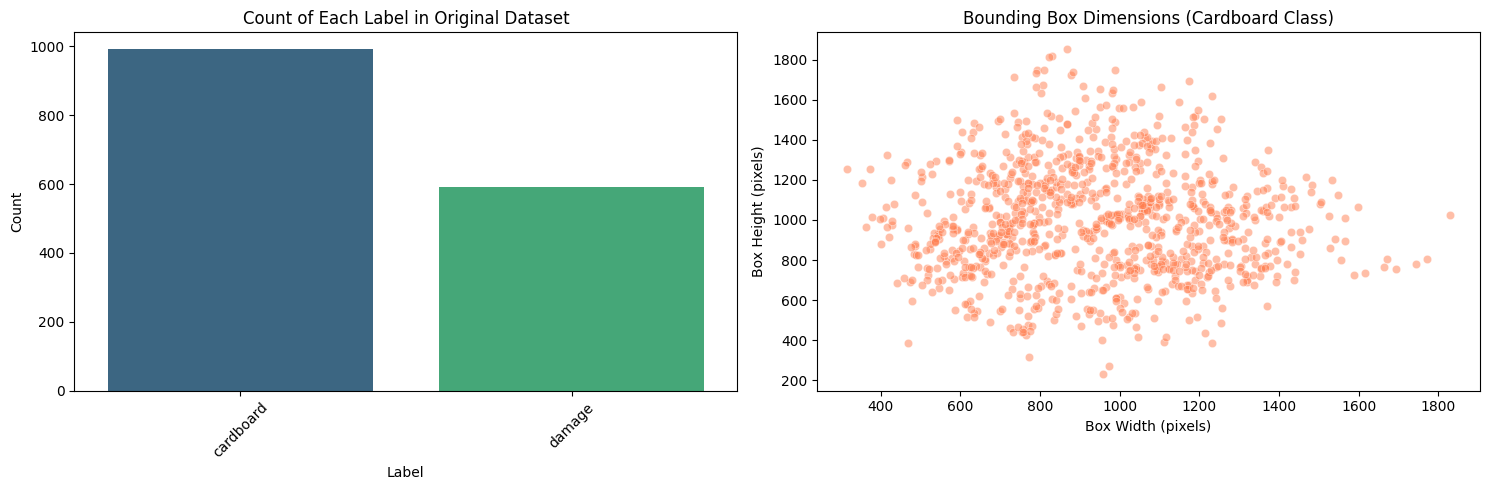


--- Dataset Summary ---
Total annotations found: 1583
label
cardboard    991
damage       592


In [19]:
import json
import glob
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Gather all JSON files from the original dataset
json_files = glob.glob('corrugated-cardboard-boxes-dataset/**/*.json', recursive=True)

data_records = []
for j_path in json_files:
    with open(j_path, 'r') as f:
        data = json.load(f)

        img_w = data.get('imageWidth')
        img_h = data.get('imageHeight')

        for shape in data.get('shapes', []):
            label = shape.get('label', 'unknown').lower()
            # Rename 'box' to 'cardboard'
            if label == 'box':
                label = 'cardboard'

            pts = shape.get('points', [])
            if len(pts) == 2:
                x1, y1 = pts[0]
                x2, y2 = pts[1]
                w = abs(x2 - x1)
                h = abs(y2 - y1)
                data_records.append({
                    'image': data.get('imagePath'),
                    'label': label,
                    'img_width': img_w,
                    'img_height': img_h,
                    'box_width': w,
                    'box_height': h
                })

df = pd.DataFrame(data_records)

# Set up the visualization
plt.figure(figsize=(15, 5))

# 1. Label Distribution
plt.subplot(1, 2, 1)
# Added hue='label' and legend=False to fix seaborn warning
sns.countplot(data=df, x='label', palette='viridis', hue='label', legend=False)
plt.title('Count of Each Label in Original Dataset')
plt.xlabel('Label')
plt.ylabel('Count')
plt.xticks(rotation=45)

# 2. Bounding Box Dimensions (for 'cardboard' only)
plt.subplot(1, 2, 2)
box_df = df[df['label'] == 'cardboard']
sns.scatterplot(data=box_df, x='box_width', y='box_height', alpha=0.5, color='coral')
plt.title('Bounding Box Dimensions (Cardboard Class)')
plt.xlabel('Box Width (pixels)')
plt.ylabel('Box Height (pixels)')

plt.tight_layout()
plt.show()

# Print a quick summary
print("\n--- Dataset Summary ---")
print(f"Total annotations found: {len(df)}")
print(df['label'].value_counts().to_string())